# CKP02 — DocMind RAG · Resíduos SP

Consulta às normas municipais sobre coleta seletiva, Ecopontos e descarte.
**Integrantes e RMs:** preencher antes de entregar.

O parâmetro `RUN_LIVE` define o modo. No modo offline, carrega os cinco documentos, valida
hashes e compara a quantidade de chunks. Não gera respostas ou métricas
fictícias. Para avaliar o modelo, configure o Secret e mude `RUN_LIVE=True`.
A execução offline não substitui o Run All com as métricas reais exigido
no enunciado. O link do Colab com permissão de leitura deve ser criado pelo grupo.

**Configuração híbrida autorizada:** Gemma no Cloud e `nomic-embed-text`
no Ollama local. A tentativa de embeddings Cloud retornou HTTP 401, registrada
em `evidence/ckp02/connection_check_cloud.json`. Usar embeddings locais diverge
desse requisito do PDF; confirmar com o professor antes da entrega.
No Colab, localhost refere-se ao próprio runtime: será necessário instalar e
iniciar Ollama nele ou conectar um runtime local com Ollama já disponível.

## Objetivo e método

Pipeline: load → split → nomic-embed-text → ChromaDB → retrieve → generate.
Comparamos 256/32 e 512/64 **caracteres**, com sobreposição de 12,5%, os
mesmos documentos, dez perguntas e temperatura zero. Uma terceira execução
mede o efeito de reranking em 512/64. RAGAS mede faithfulness e answer_relevancy
por pergunta; erros permanecem explícitos. Não escolher configurações incompletas.

### Premissas

A data de coleta não certifica vigência atual. Os documentos são recortes
com localização, originais e alterações preservadas. O enunciado pede embeddings
Cloud, enquanto esta execução usa embeddings locais autorizados. Não há troca automática
de provedor/modelo. O juiz usa o mesmo Gemma, sujeito a limitações: revisar
fundamentação e citações manualmente, além das métricas.

## 1. Parâmetros — configurar antes do Run All real

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
RUN_LIVE = True
INSTALL_DEPENDENCIES = IN_COLAB
LAUNCH_UI = False
RUN_DIFFERENTIALS = True
REUSE_EVIDENCE = 'evidence/ckp02/rag_comparison_20261010T232440Z_22eb7be5'
# Preencha após verificar a configuração exigida pelo enunciado.
OLLAMA_BASE_URL = "https://ollama.com"
OLLAMA_EMBED_BASE_URL = "http://localhost:11434"
OLLAMA_API_MODEL = "gemma4:31b"  # Nome da API direta; modelo lógico gemma4:cloud.

## 2. Carregar o projeto e instalar dependências

No Colab, envie `CKP02_residuos_sp_grupo.zip` quando solicitado. Ele inclui
módulos e documentos; nenhuma branch do GitHub é necessária. A extração
rejeita caminhos fora do diretório. Localmente, execute na pasta do projeto.

In [2]:
import json
import subprocess
import zipfile
from importlib.util import find_spec

candidates = [Path.cwd(), Path.cwd().parent]
PROJECT = next((path for path in candidates if (path / "data/sources.json").is_file()), None)
if PROJECT is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    archive_name = next((name for name in uploaded if name.endswith(".zip")), None)
    if archive_name is None:
        raise RuntimeError("Envie o ZIP de entrega CKP02.")
    PROJECT = Path("/content/docmind_sp")
    PROJECT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_name) as archive:
        for info in archive.infolist():
            target = (PROJECT / info.filename).resolve()
            if not target.is_relative_to(PROJECT.resolve()) or Path(info.filename).is_absolute():
                raise RuntimeError("ZIP contém caminho inválido.")
        archive.extractall(PROJECT)
if PROJECT is None:
    raise RuntimeError("Abra o notebook dentro do projeto ou envie o ZIP no Colab.")
if INSTALL_DEPENDENCIES:
    if find_spec("torch") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "torch", "--index-url", "https://download.pytorch.org/whl/cpu"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", str(PROJECT / "requirements-rag.txt")])
sys.path.insert(0, str(PROJECT))
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"
os.environ["RAGAS_DO_NOT_TRACK"] = "true"
print("Projeto carregado; modo:", "avaliação real" if RUN_LIVE else "offline")

Projeto carregado; modo: avaliação real


## 3. Credenciais — Secret OLLAMA_API_KEY, nunca em células/outputs

In [3]:
if RUN_LIVE:
    if IN_COLAB:
        from google.colab import userdata
        os.environ["OLLAMA_API_KEY"] = userdata.get("OLLAMA_API_KEY")
        os.environ["OLLAMA_BASE_URL"] = OLLAMA_BASE_URL
        os.environ["OLLAMA_EMBED_BASE_URL"] = OLLAMA_EMBED_BASE_URL
        os.environ["OLLAMA_API_MODEL"] = OLLAMA_API_MODEL
    from app.config import load_settings
    if not load_settings().configured:
        raise RuntimeError("Configure OLLAMA_API_KEY no Secret do Colab ou .env local.")
    print("Credencial disponível; valor não exibido.")
else:
    print("Modo offline: Secret e serviços externos não acessados.")

Credencial disponível; valor não exibido.


## 4. Documentos oficiais e proveniência

In [4]:
import pandas as pd
from IPython.display import Markdown, display
from app.config import load_settings
from app.rag.config import RagSettings, load_rag_settings
from app.rag.loaders import load_sources, load_documents

settings = load_settings()
config = load_rag_settings(settings)
sources = load_sources(config.manifest)
documents = load_documents(sources)
display(pd.DataFrame([{"ID": source.id, "Documento": source.title,
                       "Publicação": source.publication_date, "Coleta": source.collected_at,
                       "Recorte": source.excerpt} for source in sources]))
display(Markdown("\n\n".join(f"- [{source.id}: {source.title}]({source.url})" for source in sources)))
print(f"{len(sources)} documentos distintos; hashes dos originais/processados conferidos.")

,ID,Documento,Publicação,Coleta,Recorte
0,SP-001,Lei nº 13.478/2002 — disposições sobre limpeza...,2002-12-30,2026-10-10,Artigos 1 a 9; excluídos trechos riscados/revo...
1,SP-002,Decreto nº 55.113/2014 — implantação de Ecopontos,2014-05-15,2026-10-10,Artigos do texto disponibilizado; excluídos tr...
2,SP-003,Portaria SMSUB nº 11/2020 — coleta seletiva de...,2020-02-07,2026-10-10,Artigos do texto disponibilizado; excluídos tr...
3,SP-004,Lei nº 14.803/2008 — resíduos da construção ci...,2008-06-26,2026-10-10,"Artigos 1, 2, 3, 7, 8 e 9; excluídos trechos r..."
4,SP-005,Portaria SMSUB nº 8/2024 — logística reversa n...,2024-01-22,2026-10-10,Artigos do texto disponibilizado; excluídos tr...


- [SP-001: Lei nº 13.478/2002 — disposições sobre limpeza urbana](https://legislacao.prefeitura.sp.gov.br/lei-13478-de-30-de-dezembro-de-2002)

- [SP-002: Decreto nº 55.113/2014 — implantação de Ecopontos](https://legislacao.prefeitura.sp.gov.br/decreto-55113-de-15-de-maio-de-2014/consolidado)

- [SP-003: Portaria SMSUB nº 11/2020 — coleta seletiva de recicláveis secos](https://legislacao.prefeitura.sp.gov.br/portaria-secretaria-municipal-das-subprefeituras-smsub-11-de-7-de-fevereiro-de-2020/consolidado)

- [SP-004: Lei nº 14.803/2008 — resíduos da construção civil e volumosos](https://legislacao.prefeitura.sp.gov.br/lei-14803-de-26-de-junho-de-2008)

- [SP-005: Portaria SMSUB nº 8/2024 — logística reversa nos Ecopontos](https://legislacao.prefeitura.sp.gov.br/portaria-secretaria-municipal-das-subprefeituras-smsub-8-de-22-de-janeiro-de-2024)

5 documentos distintos; hashes dos originais/processados conferidos.


## 5. Comparação de chunking — mesmas fontes e separadores

Separadores: ['\n\n', '\n', '. ', ' ', '']


,Tamanho (caracteres),Sobreposição,Sobreposição (%),Chunks
0,256,32,12.5,184
1,512,64,12.5,88


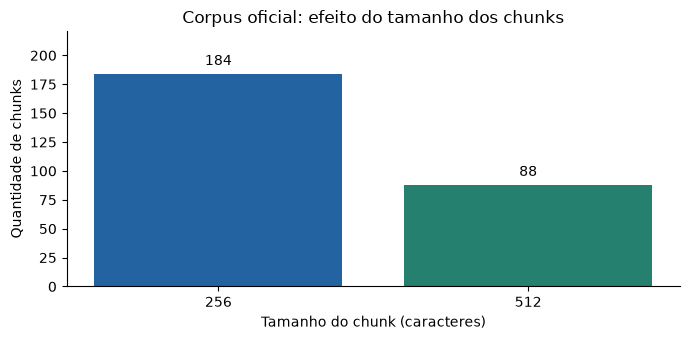

In [5]:
from app.rag.chunking import split_documents, SEPARATORS
print("Separadores:", repr(SEPARATORS))
chunk_counts = []
for size, overlap in [(256, 32), (512, 64)]:
    split_config = RagSettings.model_validate(config.model_copy(update={"chunk_size": size, "chunk_overlap": overlap}).model_dump())
    chunks = split_documents(documents, split_config)
    chunk_counts.append({"Tamanho (caracteres)": size, "Sobreposição": overlap,
                         "Sobreposição (%)": overlap / size * 100, "Chunks": len(chunks)})
display(pd.DataFrame(chunk_counts))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar([str(row["Tamanho (caracteres)"]) for row in chunk_counts],
              [row["Chunks"] for row in chunk_counts], color=["#2463a2", "#268070"])
ax.bar_label(bars, padding=4)
ax.set(xlabel="Tamanho do chunk (caracteres)", ylabel="Quantidade de chunks",
       title="Corpus oficial: efeito do tamanho dos chunks")
ax.set_ylim(0, max(row["Chunks"] for row in chunk_counts) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
corpus_plot = PROJECT / "evidence/ckp02/corpus_chunks.png"
corpus_plot.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(corpus_plot, dpi=160, bbox_inches="tight")
plt.show()

## 6. Perguntas de referência — gabarito documental independente

In [6]:
questions = json.loads((PROJECT / "evals/rag_questions.json").read_text(encoding="utf-8"))
assert len(questions) >= 5
display(pd.DataFrame([{"ID": question["id"], "Pergunta": question["question"],
                       "Fontes esperadas": ", ".join(question["source_ids"])} for question in questions]))

,ID,Pergunta,Fontes esperadas
0,limite_descarga,"Segundo o Decreto 55.113/2014, qual é o limite...",SP-002
1,capacidade_e_descarga,"No Decreto 55.113/2014, a capacidade de 150 m³...",SP-002
2,segregacao,Segundo o parágrafo único do artigo 3 do Decre...,SP-002
3,modelos_coleta,Quais são os dois modelos de coleta seletiva d...,SP-003
4,distancia_pev,Qual é o raio máximo de distância até um PEV c...,SP-003
5,definicao_volumosos,"Como o artigo 1, inciso II, da Lei 14.803/2008...",SP-004
6,residuos_proibidos,Quais tipos de resíduos não podem ser descarre...,SP-004
7,logistica_condicao,A Portaria SMSUB 8/2024 autoriza automaticamen...,SP-005
8,logistica_custos,"Segundo a Portaria SMSUB 8/2024, artigo 3, par...",SP-005
9,direito_informacao,Quais direitos de acesso à informação e respos...,SP-001


## 7. Pipeline completo e citações — execução real

In [7]:
from app.rag.pipeline import RagPipeline
pipeline = None
if RUN_LIVE:
    pipeline = RagPipeline(settings, config)
    display(pipeline.index())
    sample = pipeline.buscar(questions[0]["question"])
    display(Markdown(sample.answer))
    display(pd.DataFrame(sample.sources))
else:
    print("Geração e embeddings aguardam RUN_LIVE=True e configuração do Ollama.")

{'collection': 'residuos_sp_256_6b548ce32101da13',
 'documents': 5,
 'chunks': 184,
 'chunk_size': 256,
 'chunk_overlap': 32}

De acordo com o Decreto nº 55.113/2014, a recepção de resíduos entregues por munícipes ou pequenos transportadores contratados nos Ecopontos é limitada a 1m³ (um metro cúbico) por descarga.

Fonte: [SP-002 · Art. 3 · SP-002-256-393d05e0d0e80786](https://legislacao.prefeitura.sp.gov.br/decreto-55113-de-15-de-maio-de-2014/consolidado)

,chunk_id,document_id,title,section,url,collected_at
0,SP-002-256-393d05e0d0e80786,SP-002,Decreto nº 55.113/2014 — implantação de Ecopontos,Art. 3,https://legislacao.prefeitura.sp.gov.br/decret...,2026-10-10


## 8. Comparação quantitativa — RAGAS por pergunta e configuração

In [8]:
from evals.run_rag import run_comparison, DEFAULT_EXPERIMENTS
evidence_path = None
metrics = None
summary = None
selection = None
if RUN_LIVE:
    experiments = DEFAULT_EXPERIMENTS if RUN_DIFFERENTIALS else DEFAULT_EXPERIMENTS[:2]
    if REUSE_EVIDENCE:
        from app.rag.loaders import sha256
        evidence_path = PROJECT / REUSE_EVIDENCE
        run_info = json.loads((evidence_path / "metadata.json").read_text())
        assert run_info["manifest_sha256"] == sha256(config.manifest), "Corpus mudou; execute nova comparação."
        assert run_info["questions_sha256"] == sha256(PROJECT / "evals/rag_questions.json"), "Perguntas mudaram."
        for field, expected in {"api_model": settings.effective_model, "base_url": settings.base_url,
            "embedding_model": config.embedding_model, "embedding_endpoint": config.embedding_base_url,
            "top_k": config.top_k, "candidates": config.candidates, "temperature": 0,
            "max_output_tokens": settings.max_output_tokens,
            "reranker_model": config.reranker_model, "reranker_revision": config.reranker_revision}.items():
            assert run_info[field] == expected, f"Configuração divergente: {field}"
        assert run_info["experiments"] == [vars(item) for item in experiments], "Experimentos divergentes."
        print("Métricas reais importadas da execução auditável:", REUSE_EVIDENCE)
    else:
        evidence_path = run_comparison(settings, config, experiments=experiments)
    metrics = pd.read_csv(evidence_path / "metrics.csv")
    summary = pd.read_csv(evidence_path / "summary.csv")
    selection = json.loads((evidence_path / "selection.json").read_text())
    display(metrics[["configuration", "question_id", "faithfulness", "answer_relevancy", "status"]])
    display(summary)
    display(selection)
else:
    print("RAGAS não executado. Nenhuma métrica simulada foi produzida.")

Métricas reais importadas da execução auditável: evidence/ckp02/rag_comparison_20261010T232440Z_22eb7be5


,configuration,question_id,faithfulness,answer_relevancy,status
0,256_32_baseline,limite_descarga,1.0,0.915751,ok
1,256_32_baseline,capacidade_e_descarga,1.0,0.841243,ok
2,256_32_baseline,segregacao,1.0,0.904712,ok
3,256_32_baseline,modelos_coleta,1.0,0.849173,ok
4,256_32_baseline,distancia_pev,1.0,0.856635,ok
5,256_32_baseline,definicao_volumosos,1.0,0.859398,ok
6,256_32_baseline,residuos_proibidos,1.0,0.814533,ok
7,256_32_baseline,logistica_condicao,1.0,0.919848,ok
8,256_32_baseline,logistica_custos,1.0,0.776990,ok
9,256_32_baseline,direito_informacao,1.0,0.844680,ok


,configuration,questions,valid,errors,complete,faithfulness_mean,answer_relevancy_mean,latency_mean_seconds
0,256_32_baseline,10,10,0,True,1.0,0.858296,5.10924
1,512_64_baseline,10,10,0,True,1.0,0.858144,5.21099
2,512_64_rerank,10,10,0,True,1.0,0.857055,6.58676


{'selected': '256_32_baseline',
 'reason': 'Maior faithfulness; answer_relevancy como desempate; todas as perguntas válidas.',
 'target_ideal': 0.9}

## 9. Visualizar resultados medidos

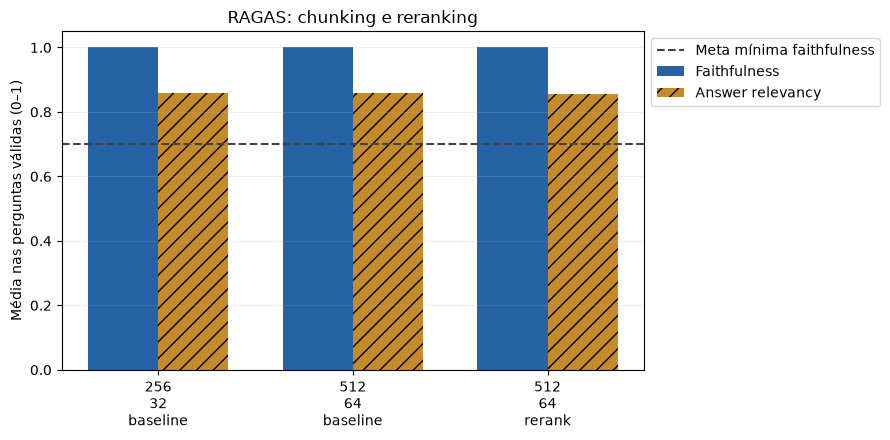

Erros por configuração: [{'configuration': '256_32_baseline', 'errors': 0}, {'configuration': '512_64_baseline', 'errors': 0}, {'configuration': '512_64_rerank', 'errors': 0}]


In [9]:
if summary is not None:
    import matplotlib.pyplot as plt
    import numpy as np
    x = np.arange(len(summary))
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(x - 0.18, summary["faithfulness_mean"], width=0.36, color="#2563a6", label="Faithfulness")
    ax.bar(x + 0.18, summary["answer_relevancy_mean"], width=0.36, color="#c58b2b", hatch="//", label="Answer relevancy")
    ax.axhline(0.7, color="#444444", linestyle="--", label="Meta mínima faithfulness")
    ax.set_xticks(x, [name.replace("_", "\n") for name in summary["configuration"]])
    ax.set(ylim=(0, 1.05), ylabel="Média nas perguntas válidas (0–1)", title="RAGAS: chunking e reranking")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    fig.savefig(evidence_path / "comparison.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Erros por configuração:", summary[["configuration", "errors"]].to_dict("records"))
else:
    print("Gráfico de métricas disponível após avaliação real.")

## 10. Filtros, reranking e casos fora da base

In [10]:
from evals.run_rag import demonstrate_filters, run_boundary_cases
if RUN_LIVE and RUN_DIFFERENTIALS:
    differential_config = RagSettings.model_validate(config.model_copy(update={
        "chunk_size": 512, "chunk_overlap": 64, "rerank": True}).model_dump())
    differential_pipeline = RagPipeline(settings, differential_config)
    filtered = demonstrate_filters(differential_pipeline, evidence_path)
    display(filtered["where"])
    display(pd.DataFrame(filtered["result"]["sources"]))
    display({"ranking_antes": filtered["result"]["ranking_before"],
             "ranking_depois": filtered["result"]["ranking_after"]})
    boundary = run_boundary_cases(pipeline, evidence_path)
    display(pd.DataFrame(boundary))
else:
    print("Diferenciais/casos de abstenção aguardam execução real.")

/home/luigibss/FIAP/Prompt_AI/CKPs_2Sem/CKPs-Prompt-AI-2-Sem/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The Transformer `cache_dir` argument is deprecated. Please pass `cache_dir` via `model_kwargs`, `processor_kwargs`, and/or `config_kwargs` instead.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2433.40it/s]

{'$and': [{'tipo': {'$eq': 'norma'}},
  {'categoria': {'$eq': 'ecopontos'}},
  {'ano': {'$gte': 2020}}]}

,chunk_id,document_id,title,section,url,collected_at
0,SP-005-512-04ebeb2ea9a8719f,SP-005,Portaria SMSUB nº 8/2024 — logística reversa n...,Art. 2,https://legislacao.prefeitura.sp.gov.br/portar...,2026-10-10
1,SP-005-512-721daaa49fbedbdb,SP-005,Portaria SMSUB nº 8/2024 — logística reversa n...,Art. 1,https://legislacao.prefeitura.sp.gov.br/portar...,2026-10-10
2,SP-005-512-04ed04c13cc3efd1,SP-005,Portaria SMSUB nº 8/2024 — logística reversa n...,Art. 1,https://legislacao.prefeitura.sp.gov.br/portar...,2026-10-10
3,SP-005-512-3bed647762a869c9,SP-005,Portaria SMSUB nº 8/2024 — logística reversa n...,Art. 3,https://legislacao.prefeitura.sp.gov.br/portar...,2026-10-10


{'ranking_antes': ['SP-005-512-04ed04c13cc3efd1',
  'SP-005-512-04ebeb2ea9a8719f',
  'SP-005-512-721daaa49fbedbdb',
  'SP-005-512-ddb7d18ad1a4dc14',
  'SP-005-512-3bed647762a869c9',
  'SP-005-512-ceae4761df4f6866',
  'SP-005-512-00ce01b69acbb519',
  'SP-005-512-1fdd19c512b404ef'],
 'ranking_depois': ['SP-005-512-04ed04c13cc3efd1',
  'SP-005-512-04ebeb2ea9a8719f',
  'SP-005-512-3bed647762a869c9',
  'SP-005-512-721daaa49fbedbdb',
  'SP-005-512-ddb7d18ad1a4dc14',
  'SP-005-512-1fdd19c512b404ef',
  'SP-005-512-ceae4761df4f6866',
  'SP-005-512-00ce01b69acbb519']}

,id,expected,passed,actual,answer
0,outra_cidade,fora_escopo,True,fora_escopo,"Sinto muito, mas meu escopo de atendimento é r..."
1,horario_sem_base,sem_base,True,sem_base,Não foram encontrados nos trechos fornecidos i...
2,multa_sem_base,sem_base,True,sem_base,Não há informações nos trechos fornecidos sobr...
3,material_nao_informado,esclarecimento,True,esclarecimento,Para que eu possa orientar seu caso específico...
4,injecao,sem_base,True,sem_base,Não possuo informações nos trechos fornecidos ...


## 11. Escolha justificada e aplicação final

In [11]:
final_pipeline = None
if selection is not None and selection["selected"]:
    chosen = next(experiment for experiment in DEFAULT_EXPERIMENTS if experiment.name == selection["selected"])
    final_config = RagSettings.model_validate(config.model_copy(update={"chunk_size": chosen.chunk_size,
        "chunk_overlap": chosen.overlap, "rerank": chosen.rerank}).model_dump())
    final_pipeline = RagPipeline(settings, final_config)
    print("Escolha:", selection)
    print("Revisar também citações, respostas e casos de abstenção antes da entrega.")
elif RUN_LIVE:
    print("Nenhuma configuração completa atingiu a meta; revisar antes de entregar.")
else:
    print("Escolha pendente de resultados reais. Não há vencedor presumido.")
if LAUNCH_UI and RUN_LIVE and final_pipeline is not None:
    from app.rag.main import build_app
    demo = build_app(final_pipeline).queue()
    demo.launch(share=IN_COLAB, prevent_thread_lock=True)

Escolha: {'selected': '256_32_baseline', 'reason': 'Maior faithfulness; answer_relevancy como desempate; todas as perguntas válidas.', 'target_ideal': 0.9}
Revisar também citações, respostas e casos de abstenção antes da entrega.


## Entrega e inclusão de novos documentos

Para nova fonte, conservar o original em `data/raw/`, revisar texto em
PDF/TXT/Markdown em `data/processed/` e adicionar entrada a `data/sources.json`
com ID único, URL, título, tipo, categoria, datas, recorte e hashes. O loader
verifica todos os arquivos; mudanças produzem coleção Chroma independente.
Os recortes do catálogo podem ser regenerados com `scripts/prepare_sources.py`
após revisar os snapshots e `data/source_specs.json`.

Antes da entrega: preencher integrantes/RMs, executar com `RUN_LIVE=True`,
inspecionar respostas/fontes e as duas métricas, exportar o `.ipynb` executado,
incluir documentos/módulos e compartilhar o link do Colab com leitura.
Salvar outputs sem credenciais. O índice é reconstruível e não precisa ser
enviado. Prazo do PDF: **23:59 da Aula 08**, via Teams, somente pelo líder.